# Notebook. Demographics

In [1]:
# Work from this notebook's folder (content/), also when the notebook is executed from the project root
# (myst build --execute, NeuroLibre), so the local modules (helpers, stats_test, ...) and ../data/ resolve.
import os
import sys

if os.path.isdir("content") and not os.path.isfile("helpers.py"):
    os.chdir("content")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from tableone import TableOne

import helpers

import plotly.express as px

In [3]:
tsv = helpers.data_path("participants.tsv")
df= pd.read_csv(tsv, sep='\t').convert_dtypes()

In [4]:
# Define the desired order of categories
group_order = ['HC', 'LBD', 'FTD', 'AD']

# Convert to ordered categorical type (the data files code healthy controls as 'Control'; the paper uses HC)
df['group'] = df['group'].replace({'Control': 'HC'})
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

## Demographics

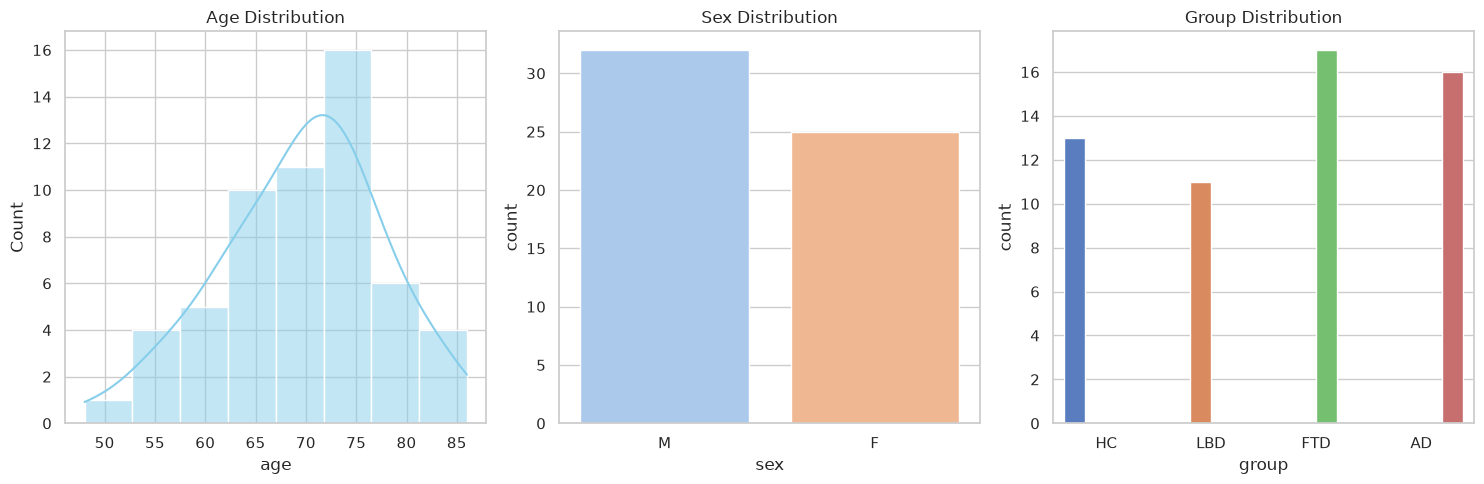

In [5]:
# Set style
sns.set_theme(style="whitegrid")

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(15,5))

# 1. Age distribution
sns.histplot(df['age'], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Age Distribution")

# 2. Sex counts
sns.countplot(x="sex", data=df, ax=axes[1], hue="sex", palette="pastel")
axes[1].set_title("Sex Distribution")

# 3. Group counts
sns.countplot(x="group", data=df, ax=axes[2], hue="group", palette="muted")

axes[2].set_title("Group Distribution")

# Adjust layout
plt.tight_layout()
plt.show()

Total subjects:

In [6]:
len(df)

57

Total subject per group:

In [7]:
print(df["group"].value_counts())

group
FTD    17
AD     16
HC     13
LBD    11
Name: count, dtype: int64


Demographics table:

In [8]:
#| label: notebook_tbl_demographics_all

columns = ["age", "sex", "MoCA"]
categorical = ["sex"]

#mean (SD) shown for all continuous vars, ANOVA/chi-square used for p-values. 
table_demographics = TableOne(
    df,
    columns=columns,
    categorical=categorical,
    groupby="group",
    pval=True,
    htest_name=True
)

# Get Pandas dataframe
table_demographics = table_demographics.tableone.copy()

# Flatten the "Grouped by group" column header down to just the group names,
# and drop the "Missing" column (always 0 here, so it adds nothing).
table_demographics.columns = table_demographics.columns.get_level_values(1)
table_demographics = table_demographics.drop(columns="Missing")

# Role per row, in the same order as table before
table_demographics.insert(0, "Role", [
    "",                   # n
    "Covariate",          # age, mean (SD)
    "Covariate",          # sex, n (%) -- F
    "Covariate",          # sex, n (%) -- M
    "Descriptive only",   # MoCA, mean (SD)
    #"Descriptive only",   # years_diagnosis, mean (SD)
])

# remove warnings from table. An alternative approach was used to validate the results.
table_demographics["Test"] = table_demographics["Test"].str.replace(
    r"Chi-squared \(warning: expected count < 5\)", "Chi-squared", regex=True)

helpers.display_table(table_demographics.reset_index().rename(columns={'level_0': 'Characteristic', 'level_1': ''}))

Characteristic,,Role,Overall,HC,LBD,FTD,AD,P-Value,Test
n,,,57,13,11,17,16,,
"age, mean (SD)",,Covariate,69.5 (8.1),65.4 (7.1),72.9 (3.4),68.6 (8.3),71.4 (9.6),0.086,One-way ANOVA
"sex, n (%)",F,Covariate,25 (43.9),7 (53.8),2 (18.2),7 (41.2),9 (56.2),0.211,Chi-squared
"sex, n (%)",M,Covariate,32 (56.1),6 (46.2),9 (81.8),10 (58.8),7 (43.8),,
"MoCA, mean (SD)",,Descriptive only,18.9 (8.2),28.8 (1.0),18.3 (7.3),18.0 (6.7),12.5 (6.3),<0.001,One-way ANOVA


In [9]:
#| label: notebook_fig_demographics_all

# Build histogram
fig = px.histogram(
    df,
    x="age",
    color="group",
    pattern_shape="sex",   # distinguishes male/female inside groups
    barmode="stack",       # stack sex inside group
    opacity=0.8,
    nbins=10,
    color_discrete_map={
    "AD": "red",
    "LBD": "orange",
    "FTD": "green",
    "HC": "blue"
    },
    width=750,
    height=500
)

# Improve layout
fig.update_layout(
    title="Age Distribution by Group and Sex",
    xaxis_title="Age",
    yaxis_title="Count",
    bargap=0.05,
    legend_title="Group / Sex"
)

fig.show()

## Removing Subject with failed segmentation

In [10]:
# Exclusion list obtained from QC the segemntation and registration of the anatomical scans. Participants with a QC level of 0 were excluded from the analyses.
exclusion_list = pd.read_csv(helpers.data_path("exclusion_list.csv")) 
print(exclusion_list)
exclusion_list = exclusion_list["participant_id"].to_list()

  participant_id                                             reason
0        sub-021  HippUnfold segmentation with a small leak arti...
1        sub-024  HippUnfold segmentation slightly failed: SRLM ...
2        sub-035  HippUnfold segmentation failed with an artifac...
3        sub-045  HippUnfold segmentation slightly failed with s...
4        sub-049  HippUnfold segmentation failed with subiculum ...
5        sub-051  HippUnfold segmentation struggled with multipl...
6        sub-057  HippUnfold segmentation failed with small leak...


In [11]:

df_removed = df.query("participant_id == @exclusion_list")
df = df.query("participant_id != @exclusion_list")

In [12]:
print("Subjects exclude because failed segmentation (QC = 0):")
print(df_removed["group"].value_counts())

Subjects exclude because failed segmentation (QC = 0):
group
FTD    4
AD     2
LBD    1
HC     0
Name: count, dtype: int64


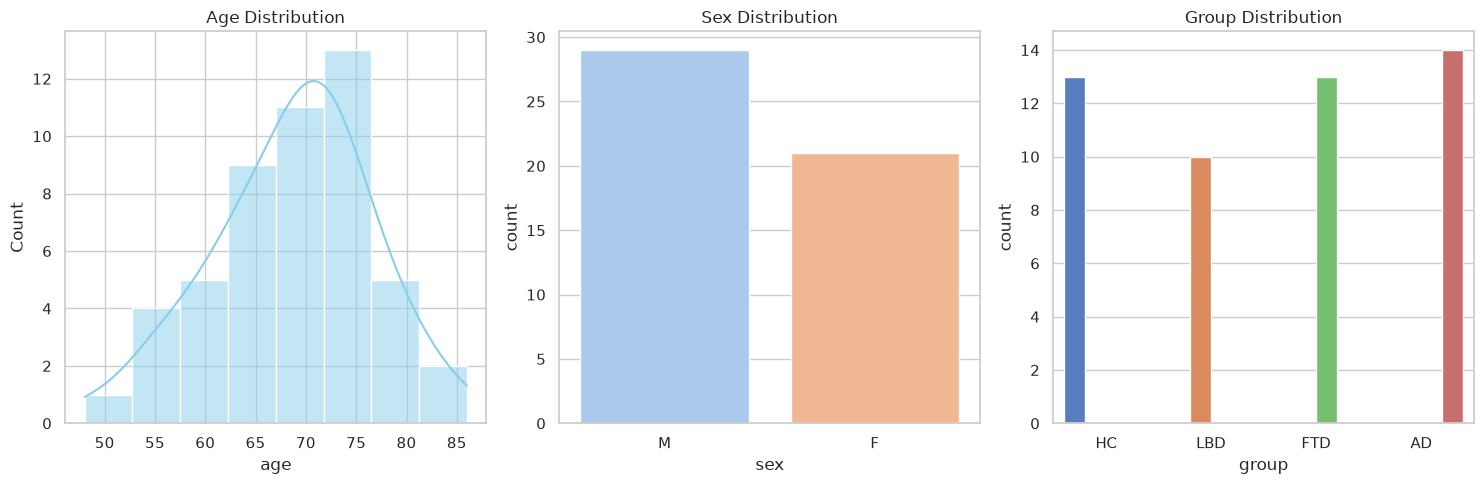

In [13]:
# Set style
sns.set_theme(style="whitegrid")

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(15,5))

# 1. Age distribution
sns.histplot(df['age'], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Age Distribution")

# 2. Sex counts
sns.countplot(x="sex", data=df, ax=axes[1], hue="sex", palette="pastel")
axes[1].set_title("Sex Distribution")

# 3. Group counts
sns.countplot(x="group", data=df, ax=axes[2], hue="group", palette="muted")

axes[2].set_title("Group Distribution")

# Adjust layout
plt.tight_layout()
plt.show()

In [14]:
# Total subject in the study after failed segementation removal
len(df)

50

In [15]:
# Total subject in each group after failed segementation removal
print(df["group"].value_counts())

group
AD     14
HC     13
FTD    13
LBD    10
Name: count, dtype: int64


In [16]:
#| label: notebook_tbl_demographics

columns = ["age", "sex", "MoCA"]
categorical = ["sex"]

#mean (SD) shown for all continuous vars, ANOVA/chi-square used for p-values. 
table_demographics = TableOne(
    df,
    columns=columns,
    categorical=categorical,
    groupby="group",
    pval=True,
    htest_name=True
)

# Get Pandas dataframe
table_demographics = table_demographics.tableone.copy()

# Flatten the "Grouped by group" column header down to just the group names,
# and drop the "Missing" column (always 0 here, so it adds nothing).
table_demographics.columns = table_demographics.columns.get_level_values(1)
table_demographics = table_demographics.drop(columns="Missing")

# Role per row, in the same order as table before
table_demographics.insert(0, "Role", [
    "",                   # n
    "Covariate",          # age, mean (SD)
    "Covariate",          # sex, n (%) -- F
    "Covariate",          # sex, n (%) -- M
    "Descriptive only",   # MoCA, mean (SD)
    #"Descriptive only",   # years_diagnosis, mean (SD)
])

# remove warnings from test table. An alternative approach was used to validate the results.
table_demographics["Test"] = table_demographics["Test"].str.replace(
    r"Chi-squared \(warning: expected count < 5\)", "Chi-squared", regex=True)

helpers.display_table(table_demographics.reset_index().rename(columns={'level_0': 'Characteristic', 'level_1': ''}))

Characteristic,,Role,Overall,HC,LBD,FTD,AD,P-Value,Test
n,,,50,13,10,13,14,,
"age, mean (SD)",,Covariate,68.7 (7.9),65.4 (7.1),72.9 (3.6),67.0 (7.9),70.2 (9.6),0.097,One-way ANOVA
"sex, n (%)",F,Covariate,21 (42.0),7 (53.8),2 (20.0),4 (30.8),8 (57.1),0.193,Chi-squared
"sex, n (%)",M,Covariate,29 (58.0),6 (46.2),8 (80.0),9 (69.2),6 (42.9),,
"MoCA, mean (SD)",,Descriptive only,19.6 (8.0),28.8 (1.0),19.2 (7.0),18.1 (5.7),12.8 (6.6),<0.001,One-way ANOVA


In [17]:
#| label: notebook_fig_demographics

# Build histogram
fig = px.histogram(
    df,
    x="age",
    color="group",
    pattern_shape="sex",   # distinguishes male/female inside groups
    barmode="stack",       # stack sex inside group
    opacity=0.8,
    nbins=10,
    color_discrete_map={
    "AD": "red",
    "LBD": "orange",
    "FTD": "green",
    "HC": "blue"
    },
    width=750,
    height=500
)

# Improve layout
fig.update_layout(
    title="Age Distribution by Group and Sex",
    xaxis_title="Age",
    yaxis_title="Count",
    bargap=0.05,
    legend_title="Group / Sex"
)

fig.show()

In [18]:
#| label: notebook_figStatic_demographics
# Static version of the demographics figure (analysed sample), used in the Word/PDF/LaTeX exports
if helpers.STATIC_FIGURE_FORMATS:
    sns.set_theme(style="white")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.histplot(data=df, x="age", hue="group", multiple="stack", bins=10, ax=axes[0])
    axes[0].set_xlabel("Age (years)")
    axes[0].set_ylabel("Count")
    axes[0].get_legend().set_title("Group")
    # grays for sex, so the colors do not repeat the group colors of the left panel
    sns.countplot(data=df, x="group", hue="sex", hue_order=["F", "M"], palette={"F": "0.35", "M": "0.7"}, ax=axes[1])
    axes[1].set_xlabel("Group")
    axes[1].set_ylabel("Count")
    axes[1].get_legend().set_title("Sex")
    fig.tight_layout()
    helpers.save_static_figure(fig, "fig_demographics")
    plt.close(fig)
    sns.set_theme()